In [229]:
import numpy as np
import netCDF4 as nc
import xarray as xr
import os
import json
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.lines as mlines
from matplotlib.colors import TwoSlopeNorm
import pandas as pd
import cartopy.crs as ccrs
# from ladcp_tools import *                  # load_all_stations, ...
# from tools import *                        # setup_map, load_satellite, load_eddies, plot_eddies
from tools_eg import *

In [246]:
EXTENT = None  # e.g. [10, 20, -42, -34]
lon_min, lon_max, lat_min, lat_max = 8, 25, -41, -34
extent = [lon_min, lon_max, lat_min, lat_max]

CRUISE_START = "2026-05-14"
CRUISE_END   = "2026-07-27"

ft = 10
# ADT colours: white exactly at 0, but each side stretched separately
# (ADT here is ~ -0.3 .. +1.5 m). Lower ADT_MIN -> darker cyclone blues,
# raise ADT_MAX -> fewer saturated anticyclone reds.
ADT_MIN, ADT_MAX = -0.3, 1.5
adt_norm = TwoSlopeNorm(vmin=ADT_MIN, vcenter=0, vmax=ADT_MAX)
levels = np.arange(ADT_MIN, ADT_MAX + 0.001, 0.02)
adt_ticks = [-0.3, 0, 0.3, 0.6, 0.9, 1.2, 1.5]

crs = ccrs.PlateCarree()
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max) / 2)


BASE = Path("/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS")
DIR_SADCP = BASE / "data/SADCP"
SADCP_FILES = {"OS150": DIR_SADCP / "WHIRLS_NB150_TOT_osite.nc",   # full cruise (README)
               "OS38": DIR_SADCP / "WHIRLS_BB38_TOT_osite.nc"}
DIR_LADCP = BASE / "data/LADCP/traitement_avec_SADCP"
DIR_SSH = BASE / "data/SSH"
DIR_EDDIES = {"TOEDDIES_better_ADT": BASE / "data/TOEDDIES/TOEDDIES_better_ADT",
              "TOEDDIES": BASE / "data/TOEDDIES/TOEDDIES"}
FNAME_BATHY = BASE / "data/bathymetry/etopo2.nc"
DIR_TRACKS = BASE / "figures/eddy_tracks"
DIR_CODE = BASE / "analysis"          # where ladcp_tools.py lives

DIR_DRIFTERS =  BASE / "data/DRIFTERS/drifters"
DIR_GEOJSON = BASE / "data/DRIFTERS/drifters_tracks.geojson"

DIR_MVP = BASE / "data/MVP_Data_processed"


# Animation
ANIM_START = "2026-07-01"                 # first drifter deployment
ANIM_END   = CRUISE_END                   # days without an ADT file are skipped
TAIL_DAYS  = 5                            # length of the track drawn behind each drifter (None = whole track)

# Drifter data: "csv" (folder of CSV snapshots, DIR_DRIFTERS) or "geojson" (DIR_GEOJSON)
DRIFTER_SOURCE = "csv"
FIRST_LAUNCH = "2026-07-01 05:00"         # fixes before this are bench tests (as in Solange's script)
FRAME_DIR = "whirls_drifters_animation"
OUT_MP4   = "whirls_drifters_animation.mp4"
FPS = 2                                   # frames (days) per second
BETAS = {"Transect 1": 10, "Transect 2": 20, "Transect 5": 22, "Transect 10": 10, "Transect 11": 15, "Transect 12": 10, "Transect 13": 15, "Transect 14": 20}
os.makedirs(FRAME_DIR, exist_ok=True)

In [247]:
# ----------------------------------------------------------------------------
# Things loaded ONCE (they don't change from day to day)
# ----------------------------------------------------------------------------
# Bathymetry
bathymetry_data = xr.open_dataset(FNAME_BATHY)
lon_subset = bathymetry_data["lon"].sel(lon=slice(lon_min, lon_max))
lat_subset = bathymetry_data["lat"].sel(lat=slice(lat_min, lat_max))
depth_subset = bathymetry_data["topo"].sel(lon=slice(lon_min, lon_max),
                                           lat=slice(lat_min, lat_max))

# File lists
daily_ssh_files = sorted(os.listdir(DIR_SSH))
eddy_files_better = sorted(os.listdir(DIR_EDDIES['TOEDDIES_better_ADT']))
eddy_files_std = sorted(os.listdir(DIR_EDDIES['TOEDDIES']))

type_SADCP = "OS38"
sadcp = nc.Dataset(SADCP_FILES[type_SADCP])


In [248]:
transect = "Transect 14"
transect_path = f'/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/data/MVP_Data_processed/{transect}/'
out_dir = f'/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/figures/mvp/{transect}/'
if not os.path.isdir(out_dir):
    os.mkdir(out_dir)

In [249]:
files = sorted(Path(transect_path).glob("*.csv"))
dfs = []
for k, f in enumerate(files):
    df = pd.read_csv(f)
    df["CAST"] = k          # one processed CSV file = one MVP cast
    dfs.append(df)
mvp_trans = pd.concat(dfs, ignore_index=True)
print(len(files), "files")

100 files


In [250]:
sadcp_all = {}
for inst in ["OS150", "OS38"]:
    s = cascade_add_time(xr.open_dataset(SADCP_FILES[inst]))
    s = s.sortby("time")
    s = s.isel(time=~s.indexes["time"].duplicated())
    sadcp_all[inst] = sadcp_for_transect(mvp_trans, s)

sadcp_tr  = sadcp_all["OS150"]          # used for positions (and in the cell below)
sadcp_mvp = sadcp_on_mvp_times(mvp_trans, sadcp_tr, max_gap="30min")

mvp_trans["LON (°E)"] = mvp_trans["LON (°E)"].fillna(pd.Series(sadcp_mvp["LONGITUDE"].values, index=mvp_trans.index))
mvp_trans["LAT (°N)"] = mvp_trans["LAT (°N)"].fillna(pd.Series(sadcp_mvp["LATITUDE"].values, index=mvp_trans.index))

print("MVP samples without position:", mvp_trans["LAT (°N)"].isna().sum(), "of", len(mvp_trans))

MVP samples without position: 0 of 418500


In [251]:
# OS150 above Z_SPLIT (150 m), OS38 below: sadcp_window keeps the right depths for each
a = sadcp_window("OS150", sadcp=cascade_to_window_format(sadcp_all["OS150"], pgood_min=50))
b = sadcp_window("OS38",  sadcp=cascade_to_window_format(sadcp_all["OS38"],  pgood_min=50))
print("OS150:", len(a["time"]), "profiles,", a["z"].min(), "-", a["z"].max(), "m")
print("OS38: ", len(b["time"]), "profiles,", b["z"].min(), "-", b["z"].max(), "m")

# put both on the same time axis (both are 10-min means), then stack in depth
t = np.union1d(a["time"], b["time"])
def on_t(d, key):
    out = np.full((len(t),) + d[key].shape[1:], np.nan)
    out[np.searchsorted(t, d["time"])] = d[key]
    return out

lon_a, lat_a = on_t(a, "lon"), on_t(a, "lat")
sadcp_mvp_processed = dict(
    time=t,
    lon=np.where(np.isnan(lon_a), on_t(b, "lon"), lon_a),
    lat=np.where(np.isnan(lat_a), on_t(b, "lat"), lat_a),
    z=np.concatenate([a["z"], b["z"]]),
    u=np.concatenate([on_t(a, "u"), on_t(b, "u")], axis=1),
    v=np.concatenate([on_t(a, "v"), on_t(b, "v")], axis=1))
print(len(sadcp_mvp_processed["time"]), "SADCP profiles,",
      sadcp_mvp_processed["z"].min(), "-", sadcp_mvp_processed["z"].max(), "m")

Calculating Mean
  ! PGOOD_ADCP is all 0 in this file -> PGOOD mask skipped
Calculating Mean
OS150: 148 profiles, 24.260000228881836 - 144.25999450683594 m
OS38:  148 profiles, 167.4600067138672 - 983.4600219726562 m
148 SADCP profiles, 24.260000228881836 - 983.4600219726562 m


eddies crossed: ['C (12 km from track)']
100 casts used


/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/analysis/tools_eg.py:1196: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = ax.pcolormesh(xkm, p, data, cmap=cmap, shading="nearest",


  C: Nencioli center at 272 km, outside section -> not marked


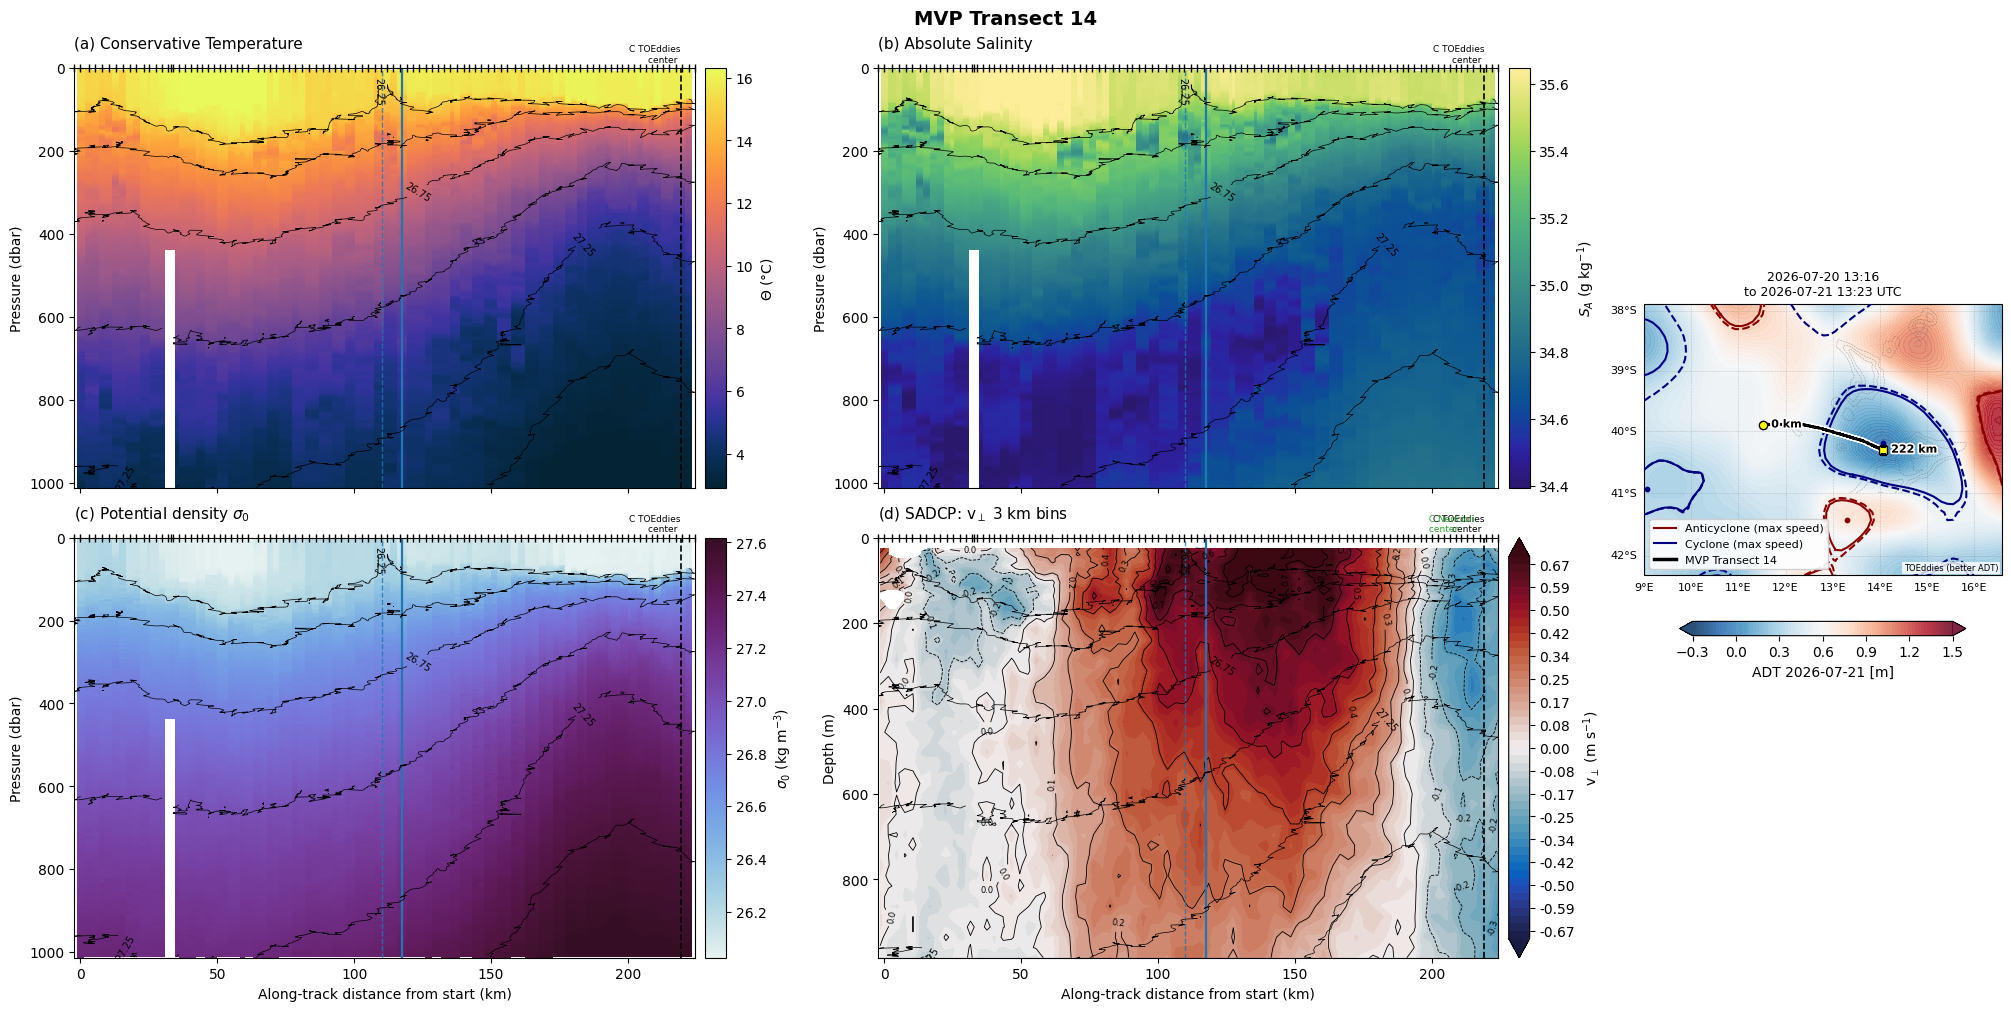

In [252]:
# ---------------- map background for the combined figure ----------------
out_dir = str(BASE / "figures/mvp") + f"/{transect}/"

date = pd.to_datetime(mvp_trans["TIME"]).median().strftime("%Y-%m-%d")
date_compact = date.replace("-", "")
ssh = load_satellite(DIR_SSH / [f for f in daily_ssh_files if date in f or date_compact in f][0])
eddy_files, eddy_source = get_eddy_files(date_compact, date)

edds = eddies_on_transect(eddy_files, mvp_trans["LON (°E)"].values, mvp_trans["LAT (°N)"].values)
print("eddies crossed:", [("C" if e["cyc"] else "AC") + f" ({e['dist_km']:.0f} km from track)" for e in edds])

# ---------------- SADCP for zeta (PV) ----------------
ds = sadcp_tr                      # ADCP subset for this transect (sadcp_mvp is ~1 GB, not needed)
zdim = ds["depth"].dims[0]
u = ds["UVEL_ADCP_CORTIDE"].transpose("time", zdim).values
v = ds["VVEL_ADCP_CORTIDE"].transpose("time", zdim).values
pg = ds["PGOOD_ADCP"].transpose("time", zdim).values

u[pg < 50] = np.nan
v[pg < 50] = np.nan

args = [ssh, eddy_files, transect, eddy_source, adt_ticks, date, levels]
# ---------------- map + Theta / S_A / sigma0 ----------------
# Along-track cut, ONLY for the transects listed here (km from the first cast). Transect 1: drop
# everything after the MVP gap (night of 29-30 June). Every other transect is kept whole.
X_MAX_KM = {"Transect 1": 110}.get(transect)
sec, fig, axs = process_transect(
    mvp_trans, adcp=sadcp_mvp_processed, cast_col="CAST",
    map_draw=draw_background,      # map_extent=extent  -> whole region instead of zoom
    map_args = args,
    title=f"MVP {transect}",
    eddy=edds,
    savepath=out_dir + f"{transect}_1_sections_hydro_adcp.png",
    x_max_km=X_MAX_KM,  # None (whole transect) except for the transects listed above
    flip_x="auto")     # orient like the map: W left / E right (S left / N right if meridional)
plt.show()

In [253]:
# ---------------- T / S anomalies on isopycnals relative to WOA (July) ----------------
# Reference = mean WOA July profile within WOA_RADIUS_KM of the TOEddies centre (as in anom_woa).
# dT(sigma) = T(sigma) - T_WOA(sigma), put back at the pressure of that isopycnal in each cast
# (Barabinot et al. 2025). Same shape as sec["CT"] (pressure x cast).
EDDY_IDX = None    # None = automatic: among the eddies whose TOEddies centre projects INSIDE the
                   # section, the one closest to the track; or an index into `edds` to force one
to_sn = make_to_sn(sec)
xk = sec["x"] / 1e3
s_centre = [float(to_sn(*e["center"])[0]) for e in edds]
inside = [k for k, s in enumerate(s_centre) if np.nanmin(xk) <= s <= np.nanmax(xk)]
if EDDY_IDX is None:
    EDDY_IDX = min(inside or range(len(edds)), key=lambda k: edds[k]["dist_km"])
for k, e in enumerate(edds):
    print(f"  eddy {k}: {'C ' if e['cyc'] else 'AC'} centre at x = {s_centre[k]:.0f} km "
          f"({'inside' if k in inside else 'OUTSIDE'} the section, {np.nanmin(xk):.0f}-{np.nanmax(xk):.0f} km), "
          f"{e['dist_km']:.0f} km from the track" + ("   <- studied" if k == EDDY_IDX else ""))
eddy = edds[EDDY_IDX]
print(f"eddy studied: {'cyclone' if eddy['cyc'] else 'anticyclone'}, TOEddies centre "
      f"{eddy['center'][0]:.3f}°E, {eddy['center'][1]:.3f}°N")

woa_ref, woa_lons, woa_lats = woa_reference_around(*eddy["center"], radius_km=WOA_RADIUS_KM)
print(f"WOA reference: {len(woa_lons)} grid points within {WOA_RADIUS_KM} km ({woa_ref['file']}), "
      f"0-{woa_ref['p'].max():.0f} dbar, sigma0 {woa_ref['sig0'].min():.3f}..{woa_ref['sig0'].max():.3f}")

anoms_woa = dict(CT=iso_anomaly(woa_ref, sec, "CT"),       # °C
                 SA=iso_anomaly(woa_ref, sec, "SA"),       # g/kg
                 sig0=iso_anomaly(woa_ref, sec, "sig0"))   # kg/m3, at constant pressure
for k, a in anoms_woa.items():
    print(f"  {k:4s} anomaly: {np.nanmin(a):+.3f} .. {np.nanmax(a):+.3f}, "
          f"{np.isfinite(a).mean() * 100:.0f}% of the section filled")
n_light = (sec["sig0"] < woa_ref["sig0"].min()).sum()
print(f"  {n_light / np.isfinite(sec['sig0']).sum() * 100:.0f}% of the section is lighter than the "
      f"lightest WOA water (sigma0 < {woa_ref['sig0'].min():.3f}) -> no isopycnal anomaly there")


  eddy 0: C  centre at x = 219 km (inside the section, -2-224 km), 12 km from the track   <- studied
eddy studied: cyclone, TOEddies centre 14.062°E, -40.188°N
WOA reference: 52 grid points within 100 km (woa23_decav_t07_04.nc), 0-1517 dbar, sigma0 26.283..27.621
  CT   anomaly: -1.524 .. +1.713, 85% of the section filled
  SA   anomaly: -0.300 .. +0.318, 85% of the section filled
  sig0 anomaly: -0.381 .. +0.421, 98% of the section filled
  12% of the section is lighter than the lightest WOA water (sigma0 < 26.283) -> no isopycnal anomaly there


zeta/f, upper 300 m: min -0.40 (anticyclonic), max 0.38 (cyclonic)


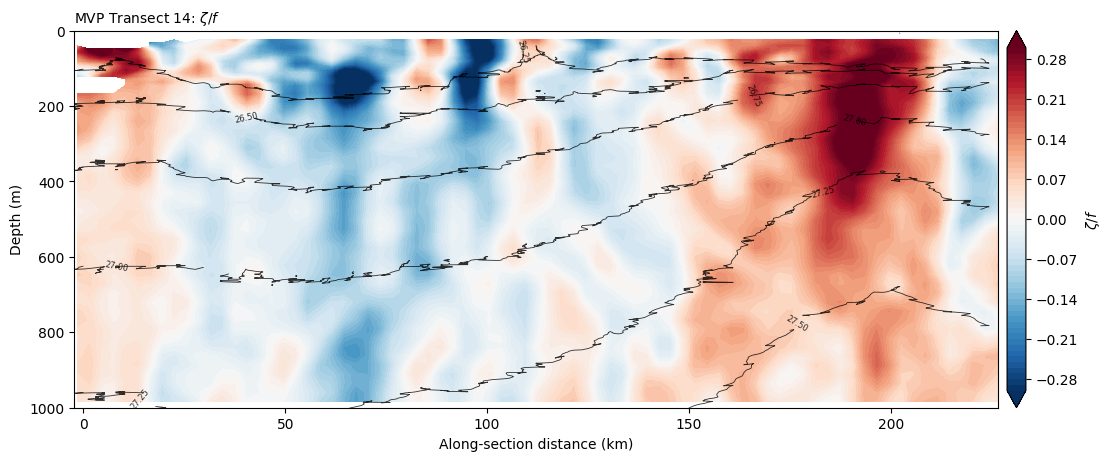

In [254]:
# ---------------- normalized relative vorticity zeta/f from SADCP ----------------
# v_perp (+ to the LEFT of the direction of motion) in DX_KM bins on the section axis, smoothed,
# zeta = d v_perp / dx (Rudnick, as in Barabinot 2025), f at each bin's latitude.
DX_KM    = DS_KM     # along-track bin (km), same 3 km bins as panel (d)
SMOOTH_X = 3         # running mean over this many bins along x before differentiating (1 = none)
SMOOTH_Z = 3         # running mean over this many SADCP levels in depth (1 = none)
RO_LIM   = 0.3       # colour limit for zeta/f
ZMAX     = 1000      # m, bottom of the plots (and of the EPV grid)
FLIP_X   = auto_flip(sec["xdir"])                          # same orientation as the section figure
XLIM     = (20, 103) if transect == "Transect 1" else None # km shown on the zeta and EPV figures

vort = section_vorticity(sec, sadcp_mvp_processed, dx_km=DX_KM, smooth_x=SMOOTH_X, smooth_z=SMOOTH_Z)
top = vort["z"] <= 300
print(f"zeta/f, upper 300 m: min {np.nanmin(vort['ro'][:, top]):.2f} (anticyclonic), "
      f"max {np.nanmax(vort['ro'][:, top]):.2f} (cyclonic)")


def set_x(ax):
    """Same x range and orientation on every figure below."""
    if XLIM is not None:
        ax.set_xlim(*XLIM)
    if FLIP_X and not ax.xaxis_inverted():
        ax.invert_xaxis()


fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
ro_levels = np.linspace(-RO_LIM, RO_LIM, int(RO_LIM * 200) + 1)
pc = ax.contourf(vort["x"], vort["z"], vort["ro"].T, cmap="RdBu_r", levels=ro_levels, extend="both")
sig_lev = np.arange(np.floor(np.nanmin(sec["sig0"]) * 4) / 4, np.nanmax(sec["sig0"]), 0.25)
cs2 = ax.contour(sec["x"] / 1e3, sec["p"], sec["sig0"], levels=sig_lev,      # p (dbar) ~ z (m)
                 colors="black", linewidths=0.6, alpha=0.8)
ax.clabel(cs2, fmt="%.2f", fontsize=6)
ax.set_ylim(ZMAX, 0)
set_x(ax)
ax.set_xlabel("Along-section distance (km)")
ax.set_ylabel("Depth (m)")
fig.colorbar(pc, ax=ax, pad=0.01, extend="both").set_label(r"$\zeta / f$")
ax.set_title(rf"MVP {transect}: $\zeta/f$", loc="left", fontsize=10)
fig.savefig(out_dir + f"{transect}_2_zeta_over_f.png", dpi=300)
plt.show()


In [255]:
# ---------------- Ertel PV on the section (Barabinot et al. 2025) ----------------
#   EPV   = (f + zeta) N^2  -  (dv_perp/dz)(db/dx)
#   EPV_z = (f + zeta) N^2              vertical part
#   EPV_x = -(dv_perp/dz)(db/dx)        horizontal (baroclinic) part
# zeta and v_perp from the cell above, b = -g (rho_theta - rho0)/rho0 from the MVP sigma0.
# Common grid: the DX_KM bins of zeta and DZ_EPV-m depth bins (section_epv in tools_eg.py).
DZ_EPV = 8.0           # m, depth bins of the common grid

epv = section_epv(sec, vort, dz=DZ_EPV, zmax=ZMAX)
EPV_x, EPV_z = epv["EPV_x"], epv["EPV_z"]
ok = np.isfinite(EPV_x) & np.isfinite(EPV_z)
print(f"grid: {len(epv['x'])} x-bins ({DX_KM:.0f} km) x {len(epv['z'])} z-bins ({DZ_EPV:.0f} m), "
      f"{epv['z'][0]:.0f}-{epv['z'][-1]:.0f} m; EPV defined on {ok.mean() * 100:.0f}% of it")
print(f"EPV_z: median {np.nanmedian(EPV_z):.2e} s^-3 (sign of f: stable water has EPV_z < 0 here)")
print(f"EPV_x > 0 (opposite sign to f, as thermal wind implies) on "
      f"{(EPV_x[ok] > 0).mean() * 100:.0f}% of the points; median |EPV_x/EPV_z| = "
      f"{np.nanmedian(np.abs(EPV_x[ok] / EPV_z[ok])):.2f}")


grid: 77 x-bins (3 km) x 120 z-bins (8 m), 24-976 m; EPV defined on 97% of it
EPV_z: median -8.41e-10 s^-3 (sign of f: stable water has EPV_z < 0 here)
EPV_x > 0 (opposite sign to f, as thermal wind implies) on 69% of the points; median |EPV_x/EPV_z| = 0.01


In [256]:
# ---------------- EPV_z anomaly on isopycnals, and the EPV-based eddy core ----------------
# dEPV_z(sigma0) = EPV_z(sigma0) - f N^2_ref(sigma0): N^2_ref of the background ON THE SAME
# ISOPYCNAL (Barabinot et al. eqs. 11, 14). R = dEPV_z / EPV_x.
# Core (sect. 4.5) = connected region around the eddy centre where dEPV_z (of the eddy's sign)
# > BETA |EPV_x|. Background CTD: data/CTD/ctd_reference_profile.nc (make_ctd_reference_profile.py).
from make_ctd_reference_profile import load_ctd_reference

BETA = BETAS[transect]             # threshold on |dEPV_z / EPV_x|
EPV_REFS = ["CTD"]      # backgrounds for dEPV_z: "CTD" and/or "WOA"
CORE_REF = "CTD"        # background whose core is used for the eddy characteristics

ctd_ref, ref_used = load_ctd_reference(BASE / "data/CTD/ctd_reference_profile.nc")[:2]
backgrounds = {"CTD": ctd_ref, "WOA": woa_ref}
to_sn = make_to_sn(sec)

epv_anoms, cores, seeds = {}, {}, {}
for name in EPV_REFS:
    an = epv_anoms[name] = epv_anomaly_iso(epv, backgrounds[name])
    ok = np.isfinite(epv["EPV_z"])
    print(f"{name}: lightest background sigma0 {an['sig_ref_min']:.3f}; "
          f"{(epv['sig0'][ok] < an['sig_ref_min']).mean() * 100:.0f}% of the section is lighter; "
          f"dEPV_z defined on {np.isfinite(an['dEPV_z'][ok]).mean() * 100:.0f}% of it, "
          f"median |R| = {np.nanmedian(np.abs(an['R'])):.1f}")
    cores[name], seeds[name] = epv_core_mask(epv, an, eddy, to_sn, beta=BETA)
    xs, zs = epv["x"][cores[name].any(axis=1)], epv["z"][cores[name].any(axis=0)]
    if xs.size:
        print(f"  core (beta = {BETA}) from seed ({seeds[name][0]:.0f} km, {seeds[name][1]:.0f} m): "
              f"x {xs.min():.0f}-{xs.max():.0f} km, z {zs.min():.0f}-{zs.max():.0f} m")
    else:
        print(f"  no core: seed ({seeds[name][0]:.0f} km, {seeds[name][1]:.0f} m) fails beta = {BETA}")

core = cores[CORE_REF]                       # (nx, nz) on the EPV grid
core_sec = core_on_section(core, epv, sec)   # same core on the MVP grid (pressure x cast)


CTD: lightest background sigma0 25.864; 0% of the section is lighter; dEPV_z defined on 91% of it, median |R| = 31.5
  core (beta = 20) from seed (220 km, 88 m): x 122-220 km, z 64-552 m


/var/folders/lg/5krm8xnn5xv0smms_psmknp40000gn/T/ipykernel_67680/2433971773.py:40: UserWarning: The following kwargs were not used by contour: 'path_effects'
  ax.contour(x, z, core.T.astype(float), levels=[0.5], colors="red", linewidths=1.8,


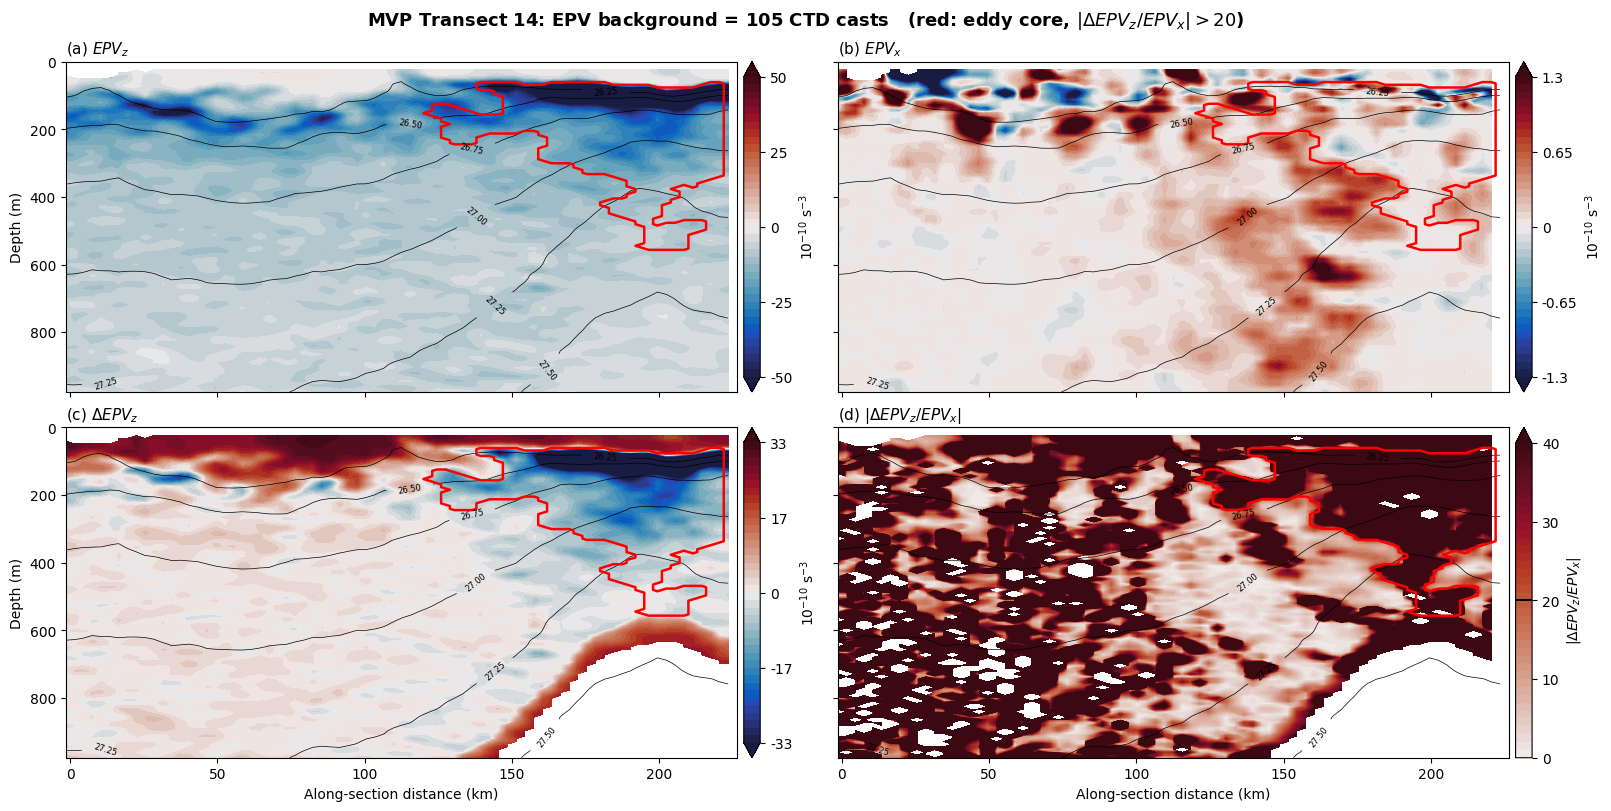

/var/folders/lg/5krm8xnn5xv0smms_psmknp40000gn/T/ipykernel_67680/2433971773.py:72: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = ax.pcolormesh(xkm, sec["p"], anoms_woa[k], cmap=cmocean.cm.balance, vmin=-lim, vmax=lim,


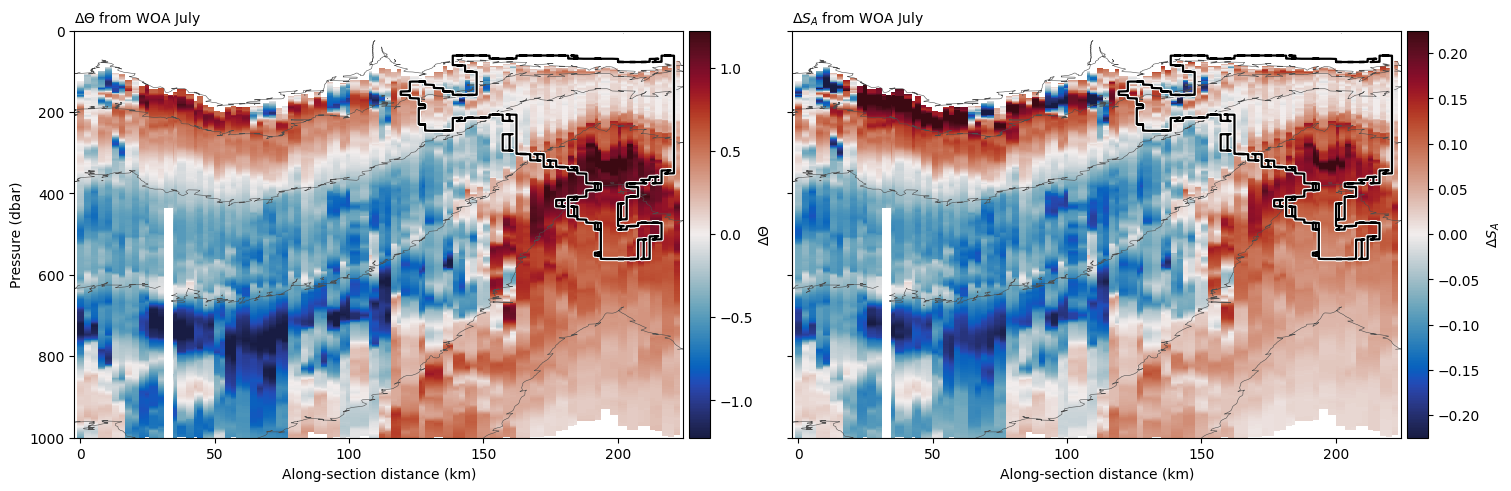

In [257]:
# ---------------- figures: EPV (one per background), and the T / S anomalies in the core ----------------
import matplotlib.patheffects as pe
EPV_SCALE = 1e-10       # plotted in units of 1e-10 s^-3
EPV_LIM = None          # colour limit for EPV_z, EPV_x, dEPV_z (in EPV_SCALE); None = 98th pct
R_MAX = 2 * BETA        # colour limit for |dEPV_z / EPV_x| in panel (d) (linear, 0 .. R_MAX)
HALO = [pe.Stroke(linewidth=3.2, foreground="white"), pe.Normal()]

def plot_epv(epv, an, title="", savepath=None, flip_x=False, zmax=ZMAX, core=None):
    """(a) EPV_z  (b) EPV_x  (c) EPV_z anomaly  (d) |dEPV_z / EPV_x| (linear), sigma0 contours.
    core: boolean (nx, nz) mask from eddy_core_mask, outlined in red on every panel."""
    import matplotlib.patheffects as pe
    x, z = epv["x"], epv["z"]
    fields = [(epv["EPV_z"], r"(a) $EPV_z$"),
              (epv["EPV_x"], r"(b) $EPV_x$"),
              (an["dEPV_z"], r"(c) $\Delta EPV_z$")]
    fig, axs = plt.subplots(2, 2, figsize=(16, 8), sharex=True, sharey=True, constrained_layout=True)
    axs = axs.ravel()
    for ax, (F, ttl) in zip(axs[:3], fields):
        Fs = F / EPV_SCALE
        lim = EPV_LIM or np.nanpercentile(np.abs(Fs), 98)
        lev = np.linspace(-lim, lim, 41)
        pc = ax.contourf(x, z, Fs.T, levels=lev, cmap=cmocean.cm.balance, extend="both")
        fig.colorbar(pc, ax=ax, pad=0.01, ticks=np.linspace(-lim, lim, 5),
                     format="%.2g").set_label(r"$10^{-10}$ s$^{-3}$")
        ax.set_title(ttl, loc="left", fontsize=11)
    absR = np.abs(an["R"])
    lev = np.linspace(0, R_MAX, 41)
    pc = axs[3].contourf(x, z, absR.T, levels=lev, cmap=cmocean.cm.amp, extend="max")
    cb = fig.colorbar(pc, ax=axs[3], pad=0.01, ticks=np.linspace(0, R_MAX, 5))
    cb.set_label(r"$|\Delta EPV_z / EPV_x|$")
    cb.ax.axhline(BETA, color="k", lw=1.5)                       # beta marked on the colour bar
    axs[3].set_title(rf"(d) $|\Delta EPV_z / EPV_x|$",
                     loc="left", fontsize=11)
    sig_lev = np.arange(np.floor(np.nanmin(epv["sig0"]) * 4) / 4, np.nanmax(epv["sig0"]), 0.25)
    for ax in axs:
        cs = ax.contour(x, z, epv["sig0"].T, levels=sig_lev, colors="k", linewidths=0.5)
        ax.clabel(cs, cs.levels, fontsize=6, fmt="%.2f")
        # ax.contour(x, z, epv["zeta"].T, levels=[0], colors="0.4", linewidths=1, linestyles="--")
        if core is not None and core.any():
            ax.contour(x, z, core.T.astype(float), levels=[0.5], colors="red", linewidths=1.8,
                       path_effects=[pe.Stroke(linewidth=3.2, foreground="white"), pe.Normal()])
        ax.set_ylim(min(zmax, z[-1]), 0)
    if flip_x:
        axs[0].invert_xaxis()
    for ax in axs[2:]:
        ax.set_xlabel("Along-section distance (km)")
    for ax in axs[::2]:
        ax.set_ylabel("Depth (m)")
    if core is not None:
        title += rf"   (red: eddy core, $|\Delta EPV_z / EPV_x| > {BETA}$)"
    fig.suptitle(title, fontsize=13, fontweight="bold")
    if savepath:
        fig.savefig(savepath, dpi=300)
    return fig, axs



for name, an in epv_anoms.items():
    ref_txt = "WOA July" if name == "WOA" else f"{len(ref_used)} CTD casts"
    fig, axs = plot_epv(epv, an, title=f"MVP {transect}: EPV background = {ref_txt}",
                        savepath=None, core=cores[name])
    for ax in axs:
        set_x(ax)
    fig.savefig(out_dir + f"{transect}_epv_{name.lower()}ref.png", dpi=300)
    plt.show()

# T / S anomalies relative to WOA with the core used for the characteristics
xkm = sec["x"] / 1e3
fig, axc = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True, constrained_layout=True)
for ax, k, lab in [(axc[0], "CT", r"$\Delta\Theta$"), (axc[1], "SA", r"$\Delta S_A$")]:
    lim = np.nanpercentile(np.abs(anoms_woa[k]), 99)
    pc = ax.pcolormesh(xkm, sec["p"], anoms_woa[k], cmap=cmocean.cm.balance, vmin=-lim, vmax=lim,
                       shading="nearest")
    fig.colorbar(pc, ax=ax, pad=0.01, label=lab)
    ax.contour(xkm, sec["p"], sec["sig0"], levels=sig_lev, colors="0.3", linewidths=0.4)
    if core_sec.any():
        cs = ax.contour(xkm, sec["p"], core_sec.astype(float), levels=[0.5], colors="k", linewidths=1.6)
        cs.set_path_effects(HALO)
    ax.set_title(f"{lab} from WOA July", loc="left", fontsize=10)
    ax.set_xlabel("Along-section distance (km)")
    set_x(ax)
axc[0].set_ylim(ZMAX, 0)
axc[0].set_ylabel("Pressure (dbar)")
plt.show()


zeta/f, upper 300 m: min -0.40 (anticyclonic), max 0.38 (cyclonic)


/var/folders/lg/5krm8xnn5xv0smms_psmknp40000gn/T/ipykernel_67680/1480680719.py:33: UserWarning: The following kwargs were not used by contour: 'path_effects'
  ax.contour(epv["x"], epv["z"], core.T.astype(float), levels=[0.5], colors="orange", linewidths=1.8,


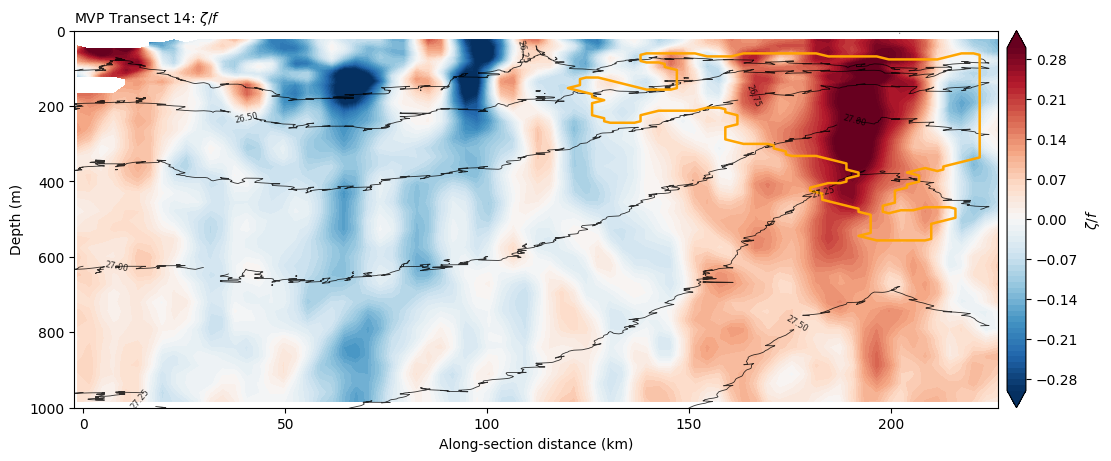

In [258]:
# ---------------- normalized relative vorticity zeta/f from SADCP ----------------
# v_perp (+ to the LEFT of the direction of motion) in DX_KM bins on the section axis, smoothed,
# zeta = d v_perp / dx (Rudnick, as in Barabinot 2025), f at each bin's latitude.
DX_KM    = DS_KM     # along-track bin (km), same 3 km bins as panel (d)
SMOOTH_X = 3         # running mean over this many bins along x before differentiating (1 = none)
SMOOTH_Z = 3         # running mean over this many SADCP levels in depth (1 = none)
RO_LIM   = 0.3       # colour limit for zeta/f
ZMAX     = 1000      # m, bottom of the plots (and of the EPV grid)
FLIP_X   = auto_flip(sec["xdir"])                          # same orientation as the section figure
XLIM     = (20, 103) if transect == "Transect 1" else None # km shown on the zeta and EPV figures

vort = section_vorticity(sec, sadcp_mvp_processed, dx_km=DX_KM, smooth_x=SMOOTH_X, smooth_z=SMOOTH_Z)
top = vort["z"] <= 300
print(f"zeta/f, upper 300 m: min {np.nanmin(vort['ro'][:, top]):.2f} (anticyclonic), "
      f"max {np.nanmax(vort['ro'][:, top]):.2f} (cyclonic)")


def set_x(ax):
    """Same x range and orientation on every figure below."""
    if XLIM is not None:
        ax.set_xlim(*XLIM)
    if FLIP_X and not ax.xaxis_inverted():
        ax.invert_xaxis()


fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
ro_levels = np.linspace(-RO_LIM, RO_LIM, int(RO_LIM * 200) + 1)
pc = ax.contourf(vort["x"], vort["z"], vort["ro"].T, cmap="RdBu_r", levels=ro_levels, extend="both")
sig_lev = np.arange(np.floor(np.nanmin(sec["sig0"]) * 4) / 4, np.nanmax(sec["sig0"]), 0.25)
cs2 = ax.contour(sec["x"] / 1e3, sec["p"], sec["sig0"], levels=sig_lev,      # p (dbar) ~ z (m)
                 colors="black", linewidths=0.6, alpha=0.8)
if core is not None and core.any():
    ax.contour(epv["x"], epv["z"], core.T.astype(float), levels=[0.5], colors="orange", linewidths=1.8,
                       path_effects=[pe.Stroke(linewidth=3.2, foreground="white"), pe.Normal()])
ax.clabel(cs2, fmt="%.2f", fontsize=6)
ax.set_ylim(ZMAX, 0)
set_x(ax)
ax.set_xlabel("Along-section distance (km)")
ax.set_ylabel("Depth (m)")
fig.colorbar(pc, ax=ax, pad=0.01, extend="both").set_label(r"$\zeta / f$")
ax.set_title(rf"MVP {transect}: $\zeta/f$", loc="left", fontsize=10)
fig.savefig(out_dir + f"{transect}_2_zeta_over_f.png", dpi=300)
plt.show()


In [259]:
# ---------------- eddy characteristics (from the EPV core above) ----------------
# Velocities: SADCP cross-track velocity v_perp (+ to the LEFT of the direction of motion).
# v_perp is a LOWER BOUND of the azimuthal speed when the track misses the centre (see the
# cross-track offset of the Nencioli centre).
V_LAYER = NEN_LAYER                    # m: layer for the radius / Rossby number (30-200 m)

clon, clat = eddy["center"]
sense = "cyclone" if eddy["cyc"] else "anticyclone"

# ---- centre: Nencioli (SADCP fixes inside the TOEddies outer contour, V_LAYER mean) ----
nen = nencioli_eddy(eddy, sadcp_mvp_processed, layer=V_LAYER)
s_toe, n_toe = (float(v) for v in to_sn(clon, clat))
nen_ok = nen is not None and not nen["edge"]
s_c, n_c = (float(v) for v in to_sn(nen["lon"], nen["lat"])) if nen_ok else (s_toe, n_toe)

# ---- radius and max speed: v_perp extrema across the core ----
xv, zv, V = vort["x"], vort["z"], vort["v_perp"]
lay = (zv >= V_LAYER[0]) & (zv <= V_LAYER[1])
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    V_lay = np.nanmean(V[:, lay], axis=1)
x_core = epv["x"][core.any(axis=1)]
R_out = contour_radius_km(eddy["outer"], clon, clat)
if x_core.size:                        # search the extrema over the core +- R_out
    win = (xv >= x_core.min() - R_out) & (xv <= x_core.max() + R_out)
else:
    win = np.abs(xv - s_c) <= 1.5 * R_out
i_pos = np.flatnonzero(win)[np.nanargmax(V_lay[win])]
i_neg = np.flatnonzero(win)[np.nanargmin(V_lay[win])]
R_sadcp = abs(xv[i_pos] - xv[i_neg]) / 2
V_lay_max = 0.5 * (abs(V_lay[i_pos]) + abs(V_lay[i_neg]))
lo, hi = sorted((i_pos, i_neg))
sub = np.abs(V[max(lo - 1, 0):hi + 2])  # max |v_perp| at any depth, between the extrema (+- 1 bin)
ix, iz = np.unravel_index(np.nanargmax(sub), sub.shape)
V_max, z_vmax, x_vmax = sub[ix, iz], zv[iz], xv[max(lo - 1, 0) + ix]

# ---- Rossby number ----
f_c = 2 * OMEGA * np.sin(np.deg2rad(clat))
Ro_bulk = V_lay_max / (abs(f_c) * R_sadcp * 1e3)
inner = np.abs(xv - s_c) <= max(R_sadcp / 2, vort["dx_km"])
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    ro_core = float(np.nanmean(vort["ro"][inner][:, lay]))
sense_sadcp = "cyclone" if ro_core > 0 else "anticyclone"     # zeta/f > 0 = cyclonic

# ---- T / S anomaly extrema (WOA) INSIDE the EPV core ----
# max T/S anomaly: the point of largest |ΔΘ| in the core, and ΔS_A at that same point.
# ΔS_A also: maximum (most positive) and minimum (most negative) in the core.
depth_sec = -gsw.z_from_p(sec["p"], epv["lat0"])


def core_extreme(var, how):
    """(value, depth m, x km) of the extreme of anoms_woa[var] inside the core; None if empty.
    how: "absmax" (largest |anomaly|), "max" or "min"."""
    a = np.where(core_sec, anoms_woa[var], np.nan)
    if not np.isfinite(a).any():
        return None
    k = {"absmax": lambda a: np.nanargmax(np.abs(a)), "max": np.nanargmax, "min": np.nanargmin}[how](a)
    ip, ic = np.unravel_index(k, a.shape)
    return a[ip, ic], depth_sec[ip], xkm[ic], (ip, ic)


t_ext = core_extreme("CT", "absmax")
ts_max = None if t_ext is None else dict(dCT=t_ext[0], dSA=anoms_woa["SA"][t_ext[3]],
                                         depth=t_ext[1], x=t_ext[2])
anom_ext = {"S max": ("SA", "g/kg", "+.3f", core_extreme("SA", "max")),
            "S min": ("SA", "g/kg", "+.3f", core_extreme("SA", "min"))}

# ---- vertical extent of the EPV core ----
z_core = epv["z"][core.any(axis=0)]

# ---- print ----
# ---- when we crossed the eddy ----
# time of the MVP cast closest to the eddy centre (Nencioli if found, else TOEddies),
# and the time span of the casts that go through the EPV core
i_c = int(np.nanargmin(np.abs(xkm - s_c)))
t_cross = sec["time"][i_c]
t_core = sec["time"][core_sec.any(axis=0)]
print(f"===== MVP {transect}: eddy {EDDY_IDX} ({eddy_source}), core from the {CORE_REF} background =====")
print(f"crossing time     : {t_cross:%Y-%m-%d %H:%M} UTC (cast closest to the centre, x = {xkm[i_c]:.0f} km)"
      + (f"; casts in the EPV core: {t_core.min():%Y-%m-%d %H:%M} to {t_core.max():%Y-%m-%d %H:%M} UTC"
         if len(t_core) else ""))
print(f"sense             : {sense} (TOEddies); SADCP zeta/f in the core = {ro_core:+.2f} -> {sense_sadcp}"
      + ("" if sense_sadcp == sense else "   <-- DISAGREES"))
print(f"TOEddies centre   : {clon:.3f}°E, {clat:.3f}°N  (x = {s_toe:.0f} km, {n_toe:+.0f} km off the line)")
if nen is None:
    print("Nencioli centre   : too few SADCP fixes inside the outer contour -> TOEddies centre used")
elif nen["edge"]:
    print("Nencioli centre   : minimum on the edge of the search box -> TOEddies centre used")
else:
    d_toe = float(np.hypot(*to_xy(nen["lon"], nen["lat"], clon, clat)))
    print(f"Nencioli centre   : {nen['lon']:.3f}°E, {nen['lat']:.3f}°N  (x = {s_c:.0f} km, {n_c:+.0f} km off "
          f"the line; {d_toe:.0f} km from the TOEddies centre; {nen['n_fixes']} fixes, "
          f"{V_LAYER[0]:.0f}-{V_LAYER[1]:.0f} m)")
print(f"radius            : {R_sadcp:.0f} km (half distance between the v_perp extrema at x = {xv[i_neg]:.0f} "
      f"and {xv[i_pos]:.0f} km); TOEddies R_maxspeed "
      f"{contour_radius_km(eddy['maxspeed'], clon, clat):.0f} km, R_outer {R_out:.0f} km")
print(f"max speed         : {V_max:.2f} m/s (|v_perp| at x = {x_vmax:.0f} km); "
      f"{V_lay_max:.2f} m/s = mean of the two extrema in {V_LAYER[0]:.0f}-{V_LAYER[1]:.0f} m")
print(f"depth of max speed: {z_vmax:.0f} m")
print(f"Rossby number     : V/(|f| R) = {Ro_bulk:.2f};  zeta/f in the core ({V_LAYER[0]:.0f}-{V_LAYER[1]:.0f} m) "
      f"= {ro_core:+.2f}")
if ts_max is None:
    print("max T/S anomaly   : no WOA anomaly inside the core")
else:
    print(f"max T/S anomaly   : ΔΘ = {ts_max['dCT']:+.2f} °C, ΔS_A = {ts_max['dSA']:+.3f} g/kg at "
          f"{ts_max['depth']:.0f} m (x = {ts_max['x']:.0f} km), inside the {CORE_REF} EPV core")
for name, (var, unit, fmt, ext) in anom_ext.items():
    lab = {"S max": "max S anomaly     ", "S min": "min S anomaly     "}[name]
    if ext is None:
        print(f"{lab}: no WOA anomaly inside the core")
    else:
        val, d, x, _ = ext
        print(f"{lab}: {val:{fmt}} {unit} at {d:.0f} m (x = {x:.0f} km), inside the {CORE_REF} EPV core")
if z_core.size:
    bottom = np.isclose(z_core.max(), epv["z"][-1])
    print(f"EPV core          : {z_core.min():.0f}-{z_core.max():.0f} m -> max depth "
          + (f">= {z_core.max():.0f} m (core reaches the bottom of the EPV grid)" if bottom
             else f"{z_core.max():.0f} m"))
else:
    print("EPV core          : not found -> no max depth, no anomaly in the core")


===== MVP Transect 14: eddy 0 (TOEddies (better ADT)), core from the CTD background =====
crossing time     : 2026-07-21 13:23 UTC (cast closest to the centre, x = 224 km); casts in the EPV core: 2026-07-21 04:27 to 2026-07-21 12:58 UTC
sense             : cyclone (TOEddies); SADCP zeta/f in the core = +nan -> anticyclone   <-- DISAGREES
TOEddies centre   : 14.062°E, -40.188°N  (x = 219 km, +12 km off the line)
Nencioli centre   : 14.557°E, -40.691°N  (x = 272 km, -34 km off the line; 70 km from the TOEddies centre; 61 fixes, 30-200 m)
radius            : 34 km (half distance between the v_perp extrema at x = 212 and 142 km); TOEddies R_maxspeed 103 km, R_outer 111 km
max speed         : 0.79 m/s (|v_perp| at x = 142 km); 0.53 m/s = mean of the two extrema in 30-200 m
depth of max speed: 48 m
Rossby number     : V/(|f| R) = 0.16;  zeta/f in the core (30-200 m) = +nan
max T/S anomaly   : ΔΘ = +1.71 °C, ΔS_A = +0.267 g/kg at 307 m (x = 194 km), inside the CTD EPV core
max S anomaly     :

MVP Transect 14: water masses, % of the section area (0-1014 dbar, -2-224 km)
       ID        group  in box (% section)  drawn (% section)  also in another chosen box (% section)  in box (% of EPV core) p (dbar)  removed by depth check (% section)
  IOSTMW1         mode                 1.3                1.3                                     0.0                     0.0    2-120                                 0.0
  IOSTMW2         mode                 2.1                2.1                                     2.1                     1.5   98-320                                 0.0
     SIMW         mode                 0.0                0.0                                     0.0                     0.0        -                                 0.0
SAMW_KT97         mode                 5.4                5.4                                     5.4                     4.1  178-562                                 0.0
      SMW      surface                 0.0                0.0      

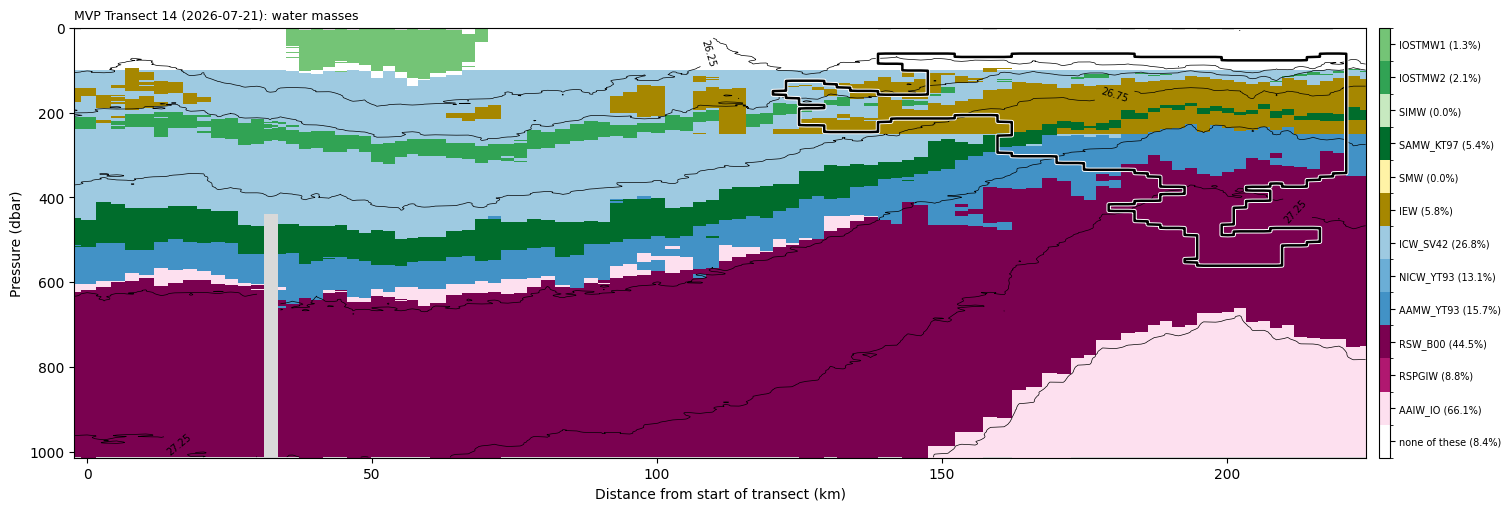

In [260]:
# ---------------- water masses on the section (boxes of water_masses.py, as in anom_water_masses) ----------------
# Pick the boxes to show by ID (all IDs: print(WM_IDS)). A sample is in a box if its (S_A, Theta)
# is inside the box AND its pressure is inside the depth range of the box's group.
# Boxes overlap: a sample in several of the chosen boxes gets the colour of the FIRST one in
# WM_SHOW (the order is the priority: first = on top), and the printout gives both shares.
# Colours: one per box, set in water_masses.py (WM_COLORS: surface yellows, central blues,
# mode greens, intermediate pinks).
# Shares are % of the section AREA (1 dbar x the along-track spacing of each cast), so unevenly
# spaced casts do not count more; "core" = the EPV core used above (CORE_REF).
from water_masses import WM_BY_ID, WM_IDS, classify, box_text, depth_text
from matplotlib.colors import ListedColormap, BoundaryNorm
import textwrap
wm_transects = {"Transect 1": ["IOSTMW2", "AAIW_X22", "RSW_B00", "IEW", "ICW_SV42", "NICW_YT93", "AAMW_YT93"],
                "Transect 2": ["IOSTMW1", "IOSTMW2", "SIMW", "SAMW_KT97", "SMW", "IEW", "ICW_SV42", "NICW_YT93", "AAMW_YT93", "RSW_B00", "RSPGIW", "AAIW_IO"],
                "Transect 5": ["IOSTMW1", "IOSTMW2", "SIMW", "SAMW_KT97", "SMW", "IEW", "ICW_SV42", "NICW_YT93", "AAMW_YT93", "RSW_B00", "RSPGIW", "AAIW_IO"],
                "Transect 11": ["IOSTMW2", "SAMW_KT97","IEW", "ICW_SV42", "NICW_YT93", "AAMW_YT93", "RSW_B00", "AAIW_IO"],
                "Transect 12": ["IOSTMW1", "IOSTMW2", "SIMW", "SAMW_KT97", "SMW", "IEW", "ICW_SV42", "NICW_YT93", "AAMW_YT93", "RSW_B00", "RSPGIW", "AAIW_IO"],
                "Transect 13": ["IOSTMW1", "IOSTMW2", "SIMW", "SAMW_KT97", "SMW", "IEW", "ICW_SV42", "NICW_YT93", "AAMW_YT93", "RSW_B00", "RSPGIW", "AAIW_IO"],
                "Transect 14": ["IOSTMW1", "IOSTMW2", "SIMW", "SAMW_KT97", "SMW", "IEW", "ICW_SV42", "NICW_YT93", "AAMW_YT93", "RSW_B00", "RSPGIW", "AAIW_IO"]}
WM_SHOW = wm_transects[transect]
                                     # (narrow boxes, e.g. mode waters, before the broad ones)
PMAX_WM = None                                                       # dbar; None = deepest MVP bin

unknown = [i for i in WM_SHOW if i not in WM_BY_ID]
assert not unknown, f"unknown water-mass IDs {unknown}; choose from {WM_IDS}"
wm_masks, wm_removed, _, valid = classify(sec)

# area weight of each sample: 1 dbar x half the distance to the neighbouring casts
xs = sec["x"] / 1e3
o = np.argsort(xs)
dx = np.empty_like(xs)
dx[o] = np.gradient(xs[o])
W = np.where(valid, np.broadcast_to(np.abs(dx)[None, :], valid.shape), 0.0)
pct = lambda m: 100 * W[m & valid].sum() / W.sum()
pct_core = lambda m: 100 * W[m & valid & core_sec].sum() / W[valid & core_sec].sum() if core_sec.any() else np.nan

# colour index: 0 = none of the chosen boxes (bottom of the legend), then WM_SHOW from the
# last (just above "none") to the first (top of the legend)
n_wm = len(WM_SHOW)
idx_of = {i: n_wm - k for k, i in enumerate(WM_SHOW)}
n_in = sum(wm_masks[i].astype(int) for i in WM_SHOW)        # how many of the chosen boxes
shown = np.full(valid.shape, np.nan)
shown[valid & (n_in == 0)] = 0
for i in WM_SHOW[::-1]:                                     # last ID first, so the FIRST ID wins
    shown[wm_masks[i] & valid] = idx_of[i]

rows = []
P = np.broadcast_to(sec["p"][:, None], valid.shape)
for k, i in enumerate(WM_SHOW):
    m = wm_masks[i] & valid
    rows.append({"ID": i, "group": WM_BY_ID[i]["group"],
                 "in box (% section)": pct(m),
                 "drawn (% section)": pct(shown == idx_of[i]),
                 "also in another chosen box (% section)": pct(m & (n_in > 1)),
                 "in box (% of EPV core)": pct_core(m),
                 "p (dbar)": f"{P[m].min():.0f}-{P[m].max():.0f}" if m.any() else "-",
                 "removed by depth check (% section)": pct(wm_removed[i] & valid)})
print(f"MVP {transect}: water masses, % of the section area (0-{np.nanmax(P[valid]):.0f} dbar, "
      f"{xs.min():.0f}-{xs.max():.0f} km)")
print(pd.DataFrame(rows).to_string(index=False, float_format="{:.1f}".format))
print(f"in none of the chosen boxes: {pct(n_in == 0):.1f}% of the section, "
      f"{pct_core(n_in == 0):.1f}% of the core;  in more than one: {pct(n_in > 1):.1f}%")

# ---- figure ----
# legend: ID and its share of the section (% of the section area inside the box; boxes overlap,
# so the shares can add up to more than 100), first ID at the top
cats = [("white", f"none of these ({pct(n_in == 0):.1f}%)")] + [
    (WM_BY_ID[i]["color"], f"{i} ({pct(wm_masks[i] & valid):.1f}%)") for i in WM_SHOW[::-1]]
xo, p = xs[o], sec["p"]
fig, ax = plt.subplots(figsize=(15, 5), constrained_layout=True)
ax.set_facecolor("0.85")                                     # grey = no data
pc = ax.pcolormesh(xo, p, shown[:, o], cmap=ListedColormap([c for c, _ in cats]),
                   norm=BoundaryNorm(np.arange(-0.5, len(cats)), len(cats)), shading="nearest",
                   rasterized=True)
cs = ax.contour(xo, p, sec["sig0"][:, o], levels=sig_lev, colors="k", linewidths=0.5)
ax.clabel(cs, cs.levels[::2], fontsize=7, fmt="%.2f")
# for e in edds:                                               # TOEddies outer contour crossings
#     for xc in crossings_on_line(e["outer"], to_sn):
#         ax.axvline(xc, color="tab:blue" if e["cyc"] else "tab:red", ls="--", lw=1.4)
if core_sec.any():                                           # EPV core
    c = ax.contour(xo, p, core_sec[:, o].astype(float), levels=[0.5], colors="k", linewidths=1.8)
    c.set_path_effects(HALO)
ax.set_ylim(PMAX_WM or np.nanmax(p), 0)
ax.set_xlim(xo.min(), xo.max())
if FLIP_X:
    ax.invert_xaxis()
ax.set_xlabel("Distance from start of transect (km)")
ax.set_ylabel("Pressure (dbar)")
ax.set_title(f"MVP {transect} ({date}): water masses",
             loc="left", fontsize=9)
cb = fig.colorbar(pc, ax=ax, ticks=range(len(cats)), pad=0.01, aspect=max(20, 3 * len(cats)))
cb.ax.set_yticklabels([lab for _, lab in cats], fontsize=7)
fig.savefig(out_dir + f"{transect}_water_masses_selected.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
WM_BY_ID

{'SMW': {'id': 'SMW',
  'name': 'Salinity Maximum Water / Subtropical Underwater',
  'group': 'surface',
  'cite': 'Barabinot et al. (2025)',
  'pub': 'σ0 < 25.6',
  'lims': {'sig0': (None, 25.6)},
  'p': (0, 250),
  'color': '#FFF3A6'},
 'AASW': {'id': 'AASW',
  'name': 'Antarctic Surface Water',
  'group': 'surface',
  'cite': 'Emery and Meincke (1986)',
  'pub': 'θ −1.0–1.0, S 34.0–34.6',
  'lims': {'SA': (34.160324571428575, 34.76315382857143),
   'theta': (-1.0, 1.0)},
  'p': (0, 250),
  'color': '#F5D33A'},
 'BBW': {'id': 'BBW',
  'name': 'Bengal Bay Water',
  'group': 'surface',
  'cite': 'Emery and Meincke (1986)',
  'pub': 'θ 25–29, S 28.0–35.0',
  'lims': {'SA': (28.132032000000002, 35.16504), 'theta': (25.0, 29.0)},
  'p': (0, 250),
  'color': '#E3BC12'},
 'ASW': {'id': 'ASW',
  'name': 'Arabian Sea Water',
  'group': 'surface',
  'cite': 'Emery and Meincke (1986)',
  'pub': 'θ 24–30, S 35.5–36.8',
  'lims': {'SA': (35.66739771428571, 36.97352777142857),
   'theta': (24.0, 3